In [5]:
!pip install nltk seaborn plotly tensorflow scikit-learn joblib

In [6]:
import pandas as pd
import numpy as np
import nltk
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [7]:
uploaded = files.upload()

Saving Covid-19 Twitter Dataset (Apr-Jun 2020).csv to Covid-19 Twitter Dataset (Apr-Jun 2020) (1).csv


In [8]:
uploaded = files.upload()

Saving Covid-19 Twitter Dataset (Apr-Jun 2021).csv to Covid-19 Twitter Dataset (Apr-Jun 2021).csv


In [9]:
uploaded = files.upload()

Saving Covid-19 Twitter Dataset (Aug-Sep 2020).csv to Covid-19 Twitter Dataset (Aug-Sep 2020).csv


In [10]:
df1 = pd.read_csv("Covid-19 Twitter Dataset (Apr-Jun 2020).csv")
df2 = pd.read_csv("Covid-19 Twitter Dataset (Apr-Jun 2021).csv")
df3 = pd.read_csv("Covid-19 Twitter Dataset (Aug-Sep 2020).csv")

df = pd.concat([df1, df2, df3], ignore_index=True)

df = df[['clean_tweet', 'sentiment', 'created_at',
         'retweet_count', 'favorite_count', 'place']]

df.dropna(subset=['clean_tweet', 'sentiment'], inplace=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total Tweets:", len(df))

Total Tweets: 409915


In [11]:
label_encoder = LabelEncoder()
df['sentiment_label'] = label_encoder.fit_transform(df['sentiment'])

print("Classes:", label_encoder.classes_)

Classes: ['neg' 'neu' 'pos']


In [12]:
df['engagement'] = df['retweet_count'] + df['favorite_count']
df['weighted_sentiment'] = df['sentiment_label'] * df['engagement']

In [13]:
MAX_WORDS = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['clean_tweet'])

sequences = tokenizer.texts_to_sequences(df['clean_tweet'])
X = pad_sequences(sequences, maxlen=MAX_LEN)

y = df['sentiment_label']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
model = Sequential([
    Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
    LSTM(128),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(patience=2, restore_best_weights=True)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
history = model.fit(
    X_train, y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/8
4100/4100 ━━━━━━━━━━━━━━━━━━━━ 50s 11ms/step - accuracy: 0.8987 - loss: 0.2590 - val_accuracy: 0.9869 - val_loss: 0.0525
Epoch 2/8
4100/4100 ━━━━━━━━━━━━━━━━━━━━ 42s 10ms/step - accuracy: 0.9865 - loss: 0.0518 - val_accuracy: 0.9882 - val_loss: 0.0481
Epoch 3/8
4100/4100 ━━━━━━━━━━━━━━━━━━━━ 43s 11ms/step - accuracy: 0.9891 - loss: 0.0394 - val_accuracy: 0.9889 - val_loss: 0.0492
Epoch 4/8
4100/4100 ━━━━━━━━━━━━━━━━━━━━ 43s 10ms/step - accuracy: 0.9918 - loss: 0.0296 - val_accuracy: 0.9886 - val_loss: 0.0555


In [17]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Final LSTM Accuracy:", round(accuracy * 100, 2), "%")

2562/2562 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9879 - loss: 0.0480
Final LSTM Accuracy: 98.79 %


2562/2562 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     22043
           1       0.99      0.99      0.99     34505
           2       0.98      0.99      0.98     25435

    accuracy                           0.99     81983
   macro avg       0.99      0.99      0.99     81983
weighted avg       0.99      0.99      0.99     81983



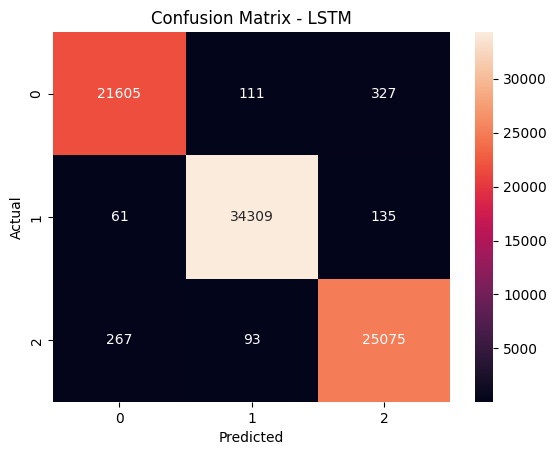

In [18]:
y_pred = model.predict(X_test)
y_pred_classes = y_pred.argmax(axis=1)

print(classification_report(y_test, y_pred_classes))

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - LSTM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [19]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

print("Logistic Regression Accuracy:",
      round(lr.score(X_test, y_test) * 100, 2), "%")

Logistic Regression Accuracy: 41.85 %


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [20]:
misinfo_keywords = [
    "fake", "hoax", "myth", "rumor", "5g",
    "conspiracy", "plandemic", "bioweapon"
]

def detect_misinfo(text):
    return int(any(word in text.lower() for word in misinfo_keywords))

df['misinfo_label'] = df['clean_tweet'].apply(detect_misinfo)

tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = tfidf.fit_transform(df['clean_tweet'])

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_tfidf, df['misinfo_label'], test_size=0.2, random_state=42
)

misinfo_model = LogisticRegression()
misinfo_model.fit(X_train_m, y_train_m)

print("Misinformation Classifier Accuracy:",
      round(misinfo_model.score(X_test_m, y_test_m)*100,2), "%")

Misinformation Classifier Accuracy: 99.95 %


In [21]:
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')

negative_daily = df[df['sentiment'] == 'neg'] \
    .groupby(df['created_at'].dt.date).size()

mean = negative_daily.mean()
std = negative_daily.std()
threshold = mean + 2 * std

negative_spikes = negative_daily[negative_daily > threshold]

print("Negative Sentiment Spikes:")
print(negative_spikes)

Negative Sentiment Spikes:
created_at
2020-04-25    1724
2020-05-04    1820
2020-05-09    1675
2020-09-27    2017
2020-09-30    1740
2020-10-01    1624
2021-05-25    1698
2021-06-03    1677
dtype: int64


In [22]:
negative_percent = (df['sentiment'] == 'neg').mean() * 100
misinfo_percent = df['misinfo_label'].mean() * 100

print("Negative Sentiment %:", round(negative_percent,2))
print("Misinformation %:", round(misinfo_percent,2))

Negative Sentiment %: 26.74
Misinformation %: 0.49


In [23]:
def policy_recommendation(neg_pct, spike_detected):
    if neg_pct > 40:
        return "Launch targeted awareness campaign."
    if spike_detected:
        return "Release official fact-check response."
    return "Public perception stable."

print("Recommendation:",
      policy_recommendation(negative_percent, len(negative_spikes)>0))

Recommendation: Release official fact-check response.


In [25]:
model.save("sentiment_model.keras")

joblib.dump(tokenizer, "tokenizer.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")
joblib.dump(misinfo_model, "misinfo_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("All files saved in new Keras format.")

All files saved in new Keras format.


In [26]:
files.download("sentiment_model.keras")
files.download("tokenizer.pkl")
files.download("label_encoder.pkl")
files.download("misinfo_model.pkl")
files.download("tfidf_vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>